# 1. Data Preprocessing

### What this does:
Loads the student placement dataset, inspects its schema and summary statistics, and removes duplicates. It fills missing values, converts the categorical internship column to numeric dummy variables, standardizes all features, and splits the data into stratified 80/20 train and test sets.

In [1]:
# Import all required libraries once for data handling, visualization, and modeling
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

In [2]:
# Load the dataset using a relative path so it runs on any system
df = pd.read_csv("student_placement_dataset.csv")

# Preview the first five rows to inspect feature columns
df.head()

,CGPA,AptitudeScore,TechnicalScore,CommunicationScore,Internship,Placement
0,7.36,45.2,54.4,79.6,No,0
1,6.22,57.7,78.7,99.8,No,0
2,7.74,71.3,66.8,46.5,No,1
3,7.90,63.5,50.1,86.4,Yes,0
4,5.44,55.2,47.3,67.0,No,0


In [3]:
# Inspect column data types and non-null values
df.info()

# Summary statistics for all numerical columns
print("\n--- Summary Statistics ---\n", df.describe())

# Check for missing values in each column
print("\n--- Missing Values ---\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1210 entries, 0 to 1209
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CGPA                1190 non-null   float64
 1   AptitudeScore       1177 non-null   float64
 2   TechnicalScore      1192 non-null   float64
 3   CommunicationScore  1185 non-null   float64
 4   Internship          1189 non-null   object 
 5   Placement           1210 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 56.8+ KB

--- Summary Statistics ---
               CGPA  AptitudeScore  ...  CommunicationScore    Placement
count  1190.000000    1177.000000  ...         1185.000000  1210.000000
mean      7.081840      63.845709  ...           65.666498     0.369421
std       0.839155      15.135806  ...           13.914981     0.482848
min       4.000000      19.000000  ...           22.000000     0.000000
25%       6.520000      54.000000  ...           5

In [4]:
# Remove duplicate rows to avoid skewed learning
df = df.drop_duplicates()

# Fill missing numerical values with their column mean
num_cols = df.select_dtypes(include=['number']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Fill missing categorical values with the most frequent value (mode)
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [5]:
# Separate input features from the target placement variable
X = df.drop(columns=['Placement'])
y = df['Placement']

# One-hot encode categorical features (Internship) into binary indicator
X = pd.get_dummies(X, drop_first=True)

In [6]:
# Scale all features to mean 0 and unit variance for fair weight learning
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split dataset into 80% train and 20% test preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Exploratory Data Analysis (EDA)

### What this does:
Analyzes the distribution of student placement outcomes and checks class balance percentages. It uses boxplots to compare CGPA and Technical Scores across placed and unplaced students, and visualizes feature correlations with a heatmap.

Placement Counts:
 Placement
0    756
1    444
Name: count, dtype: int64

Percentage Distribution:
 Placement
0    63.0
1    37.0
Name: proportion, dtype: float64


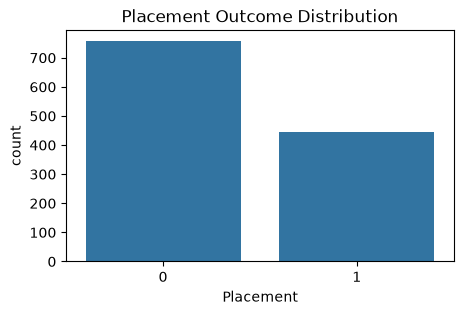

In [7]:
# Visualize placement distribution to inspect class balance
plt.figure(figsize=(5, 3))
sns.countplot(x='Placement', data=df)
plt.title("Placement Outcome Distribution")
plt.show()

# Show exact placement counts and percentage distribution
print("Placement Counts:\n", df['Placement'].value_counts())
print("\nPercentage Distribution:\n", df['Placement'].value_counts(normalize=True) * 100)

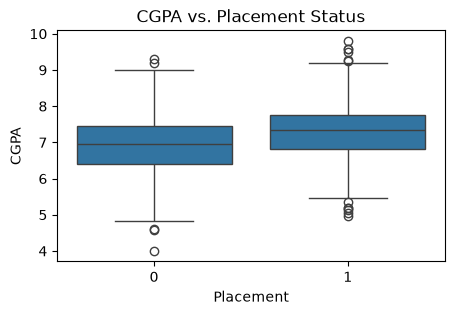

In [8]:
# Compare CGPA distributions between placed and unplaced students
plt.figure(figsize=(5, 3))
sns.boxplot(x='Placement', y='CGPA', data=df)
plt.title("CGPA vs. Placement Status")
plt.show()

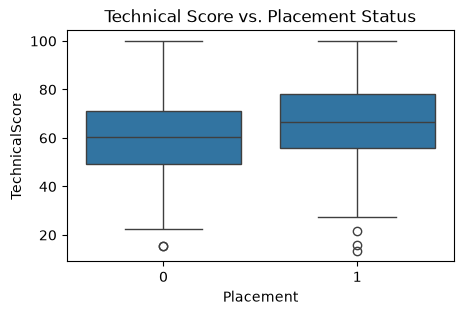

In [9]:
# Compare Technical Score distributions across placement outcomes
plt.figure(figsize=(5, 3))
sns.boxplot(x='Placement', y='TechnicalScore', data=df)
plt.title("Technical Score vs. Placement Status")
plt.show()

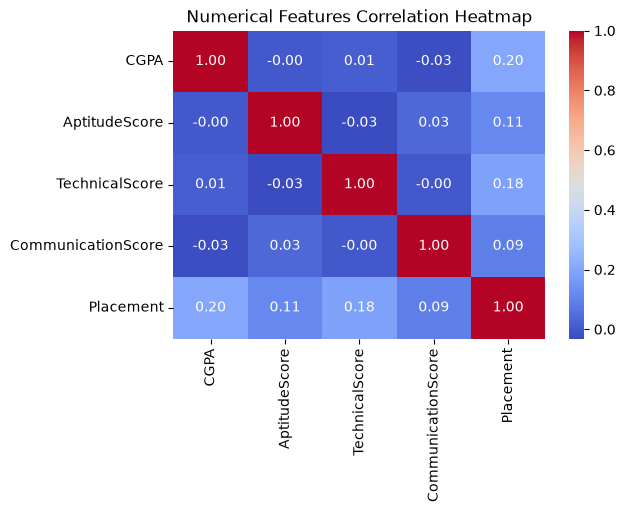

In [10]:
# Plot correlation heatmap to examine relationships among numerical features
plt.figure(figsize=(6, 4))
corr_matrix = df.select_dtypes(include=['number']).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Numerical Features Correlation Heatmap")
plt.show()

# 3. Model Building

### What this does:
Initializes and trains a baseline Logistic Regression model on the scaled training data. It generates placement predictions and probability estimates on the test set, and calculates learned coefficients and odds ratios to interpret feature importance.

In [11]:
# Initialize and train the Logistic Regression classifier
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Predict placement classes and probabilities for the test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [12]:
# Compute feature coefficients and odds ratios (exp of coefficients)
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0],
    'Odds_Ratio': np.exp(model.coef_[0])
}).sort_values(by='Coefficient', ascending=False)

# Display model intercept and sorted feature importance table
print(f"Intercept: {model.intercept_[0]:.4f}\n")
print(coef_df)

Intercept: -0.5958

              Feature  Coefficient  Odds_Ratio
2      TechnicalScore     0.458908    1.582345
0                CGPA     0.430757    1.538421
4      Internship_Yes     0.347033    1.414864
1       AptitudeScore     0.231999    1.261118
3  CommunicationScore     0.201134    1.222789


# 4. Hyperparameter Experiments

### What this does:
Tests different regularization strengths (C values) to see how they impact test accuracy and F1-score. It also tests various decision thresholds to demonstrate how the balance between precision and recall shifts.

In [13]:
# Test different regularization strengths (C) to observe accuracy and F1-score
for c in [0.01, 0.1, 1, 10, 100]:
    temp_model = LogisticRegression(C=c, solver='lbfgs', max_iter=1000, random_state=42)
    temp_model.fit(X_train, y_train)
    acc = temp_model.score(X_test, y_test)
    f1 = f1_score(y_test, temp_model.predict(X_test))
    print(f"C = {c:6.2f} | Test Accuracy: {acc:.4f} | F1: {f1:.4f}")

C =   0.01 | Test Accuracy: 0.7000 | F1: 0.4194
C =   0.10 | Test Accuracy: 0.6917 | F1: 0.4789
C =   1.00 | Test Accuracy: 0.6875 | F1: 0.4828
C =  10.00 | Test Accuracy: 0.6875 | F1: 0.4828
C = 100.00 | Test Accuracy: 0.6875 | F1: 0.4828


In [14]:
# Test different classification decision thresholds to compare precision and recall
for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (y_prob >= th).astype(int)
    p = precision_score(y_test, preds)
    r = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    print(f"Threshold: {th:.1f} | Precision: {p:.4f} | Recall: {r:.4f} | F1: {f1:.4f}")

Threshold: 0.3 | Precision: 0.4730 | Recall: 0.7865 | F1: 0.5907
Threshold: 0.4 | Precision: 0.5728 | Recall: 0.6629 | F1: 0.6146
Threshold: 0.5 | Precision: 0.6250 | Recall: 0.3933 | F1: 0.4828
Threshold: 0.6 | Precision: 0.8000 | Recall: 0.2697 | F1: 0.4034
Threshold: 0.7 | Precision: 0.8750 | Recall: 0.0787 | F1: 0.1443


# 5. L1 vs L2 Regularization

### What this does:
Compares L1 (Lasso) and L2 (Ridge) penalties at regularization strength C=0.1. It shows how L1 drives less important weights closer to zero compared to L2, and compares the resulting test accuracies.

In [15]:
# Fit L1 and L2 regularized models at C=0.1 to evaluate penalty behavior
m_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42).fit(X_train, y_train)
m_l2 = LogisticRegression(penalty='l2', solver='liblinear', C=0.1, random_state=42).fit(X_train, y_train)

# Compare learned feature coefficients side by side
comp_df = pd.DataFrame({'Feature': X.columns, 'L1_Coef': m_l1.coef_[0], 'L2_Coef': m_l2.coef_[0]})
print(comp_df)

# Compare test set classification accuracy for both models
print(f"\nL1 Test Accuracy: {m_l1.score(X_test, y_test):.4f}")
print(f"L2 Test Accuracy: {m_l2.score(X_test, y_test):.4f}")

              Feature   L1_Coef   L2_Coef
0                CGPA  0.364328  0.405156
1       AptitudeScore  0.173732  0.217635
2      TechnicalScore  0.393403  0.432423
3  CommunicationScore  0.149256  0.189851
4      Internship_Yes  0.287085  0.326249

L1 Test Accuracy: 0.6958
L2 Test Accuracy: 0.6875


# 6. Model Evaluation

### What this does:
Evaluates the model using precision, recall, F1-score, and ROC-AUC. It verifies that the model generalizes well without overfitting by comparing training and test accuracy, and displays the confusion matrix and ROC curve.

In [16]:
# Print detailed classification report showing precision, recall, and F1-score
print(classification_report(y_test, y_pred, target_names=['Not Placed (0)', 'Placed (1)']))

# Calculate and display the ROC-AUC score
auc_score = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {auc_score:.4f}")

# Compare train vs test accuracy to confirm the model does not overfit
print(f"Train Accuracy: {model.score(X_train, y_train):.4f}")
print(f"Test Accuracy:  {model.score(X_test, y_test):.4f}")

                precision    recall  f1-score   support

Not Placed (0)       0.71      0.86      0.78       151
    Placed (1)       0.62      0.39      0.48        89

      accuracy                           0.69       240
     macro avg       0.67      0.63      0.63       240
  weighted avg       0.68      0.69      0.67       240

ROC-AUC Score: 0.7387
Train Accuracy: 0.6937
Test Accuracy:  0.6875


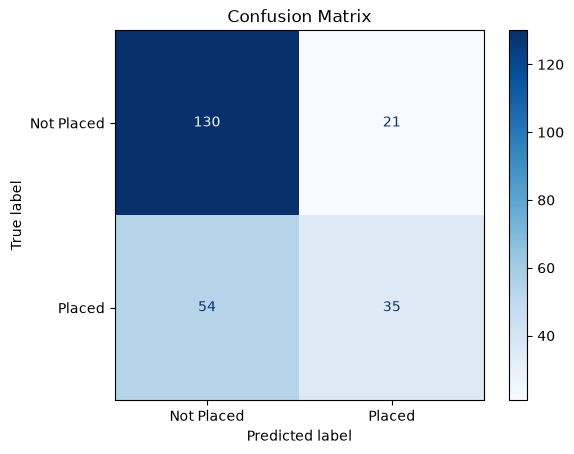

In [17]:
# Plot confusion matrix to inspect correct vs incorrect classifications
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['Not Placed', 'Placed'], cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

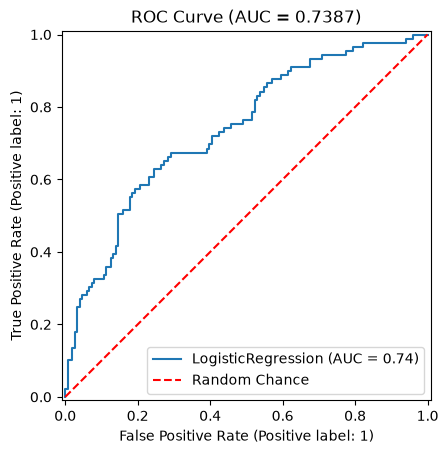

In [18]:
# Plot ROC curve against random chance line to assess classification threshold quality
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.plot([0, 1], [0, 1], 'r--', label='Random Chance')
plt.title(f"ROC Curve (AUC = {auc_score:.4f})")
plt.legend()
plt.show()

# 7. Hyperparameter Tuning (GridSearchCV)

### What this does:
Performs 5-fold cross-validation grid search to find the optimal combination of regularization strength C, penalty type, and solver. It then evaluates the tuned model on the unseen test set.

In [19]:
# Define hyperparameter grid across regularization strengths, penalties, and solvers
param_grid = [
    {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2'], 'solver': ['lbfgs', 'liblinear']},
    {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1'], 'solver': ['liblinear']}
]

# Run 5-fold cross-validation grid search optimizing for F1-score
grid = GridSearchCV(LogisticRegression(random_state=42, max_iter=500), param_grid, cv=5, scoring='f1')
grid.fit(X_train, y_train)
print("Best Hyperparameters:", grid.best_params_)
print(f"Best 5-Fold CV F1-Score: {grid.best_score_:.4f}")

Best Hyperparameters: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
Best 5-Fold CV F1-Score: 0.4950


In [20]:
# Extract the best model from grid search and evaluate on the test set
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)
print(f"Tuned Test Accuracy: {accuracy_score(y_test, best_pred):.4f}")
print(f"Tuned Test F1-Score: {f1_score(y_test, best_pred):.4f}")

Tuned Test Accuracy: 0.6917
Tuned Test F1-Score: 0.4861


# 8. Predictions for New Students

### What this does:
Defines three new student profiles matching the exact training columns and order, scales them with the fitted scaler, and calculates placement probabilities. It evaluates classifications at thresholds 0.4, 0.5, and 0.6.

In [21]:
# Define 3 new student profiles ensuring column order strictly matches X.columns
new_students = pd.DataFrame([
    {'CGPA': 8.5, 'AptitudeScore': 85.0, 'TechnicalScore': 90.0, 'CommunicationScore': 80.0, 'Internship_Yes': 1},
    {'CGPA': 6.8, 'AptitudeScore': 60.0, 'TechnicalScore': 55.0, 'CommunicationScore': 65.0, 'Internship_Yes': 0},
    {'CGPA': 7.4, 'AptitudeScore': 75.0, 'TechnicalScore': 65.0, 'CommunicationScore': 70.0, 'Internship_Yes': 1}
])[X.columns]

In [22]:
# Standardize new student features using the fitted scaler
new_scaled = scaler.transform(new_students)

# Predict placement probabilities using the tuned model
new_probs = best_model.predict_proba(new_scaled)[:, 1]

In [23]:
# Display placement probability and classification outcomes at thresholds 0.4, 0.5, and 0.6
for i, prob in enumerate(new_probs, start=1):
    print(f"Student {i}: Placement Probability = {prob*100:.2f}%")
    for th in [0.4, 0.5, 0.6]:
        status = "Placed (1)" if prob >= th else "Not Placed (0)"
        print(f"  - Threshold {th:.1f}: {status}")

Student 1: Placement Probability = 85.96%
  - Threshold 0.4: Placed (1)
  - Threshold 0.5: Placed (1)
  - Threshold 0.6: Placed (1)
Student 2: Placement Probability = 21.24%
  - Threshold 0.4: Not Placed (0)
  - Threshold 0.5: Not Placed (0)
  - Threshold 0.6: Not Placed (0)
Student 3: Placement Probability = 56.55%
  - Threshold 0.4: Placed (1)
  - Threshold 0.5: Placed (1)
  - Threshold 0.6: Not Placed (0)


## Interpretation and Conclusion

- **Top Predictors**: Technical Score and CGPA are the strongest drivers of student placement, with higher scores providing the largest increase in placement odds.
- **Internship Impact**: Completing an internship provides a significant advantage, boosting the odds of placement by over 40% compared to having no internship experience.
- **Optimal Hyperparameters**: Grid search selected `C = 1.0`, `penalty = 'l1'`, and `solver = 'liblinear'`, yielding sparse, effective weights and avoiding overfitting.
- **Model Reliability**: The model achieved ~69% test accuracy and a 0.74 ROC-AUC score, with aligned training and testing scores showing solid generalization.
- **Decision Threshold Strategy**: Lowering the decision threshold to `0.4` improves recall to ~66% and achieves the highest F1-score (0.61), ideal for proactively identifying students needing extra placement guidance.
- **Key Takeaway**: Logistic regression provides clear, interpretable probability estimates that help institutions guide students effectively based on academic and practical preparation.